# 02. Khám Phá Dữ Liệu Có Mục Tiêu (Targeted Exploratory Data Analysis - EDA)
**Học phần:** Khai thác dữ liệu (Data Mining) — Đề tài 16: Phân nhóm quốc gia theo các yếu tố hạnh phúc (World Happiness Report)  
**Nhóm thực hiện:** Nhóm 12  
---
### Đối chiếu với Mục 1.2 - Pipeline bắt buộc của đồ án:
- [x] **Bước 4:** Khám phá dữ liệu (EDA) có mục tiêu: Dùng bảng thống kê và biểu đồ để hiểu dữ liệu, phân phối, tương quan, phát hiện ngoại lệ (outliers), chuẩn bị cơ sở cho việc scale và lựa chọn thuật toán.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn tương đối độc lập môi trường
project_root = Path('..').resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

figures_dir = project_root / 'reports' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

# Định nghĩa 6 yếu tố cơ sở (Quy tắc vàng: KHÔNG đưa happiness_score vào ma trận gom cụm X)
feature_cols = [
    'gdp_per_capita',
    'social_support',
    'healthy_life_expectancy',
    'freedom',
    'generosity',
    'corruption_perception'
]

### Bảng Chú Thích Ngữ Nghĩa Các Thuộc Tính Đo Lường (World Happiness Report)
Nhằm đảm bảo tính nhất quán tuyệt đối giữa mã nguồn, tên cột dữ liệu và diễn giải trong Báo cáo Word, dưới đây là bảng đối chiếu chi tiết:

| Tên Thuộc Tính (Code & Biểu Đồ) | Tên Tiếng Việt Trong Báo Cáo | Ý Nghĩa Kinh Tế - Xã Hội Đo Lường |
| :--- | :--- | :--- |
| `gdp_per_capita` | GDP bình quân đầu người | Sức mạnh kinh tế, năng lực sản xuất và mức thu nhập thực tế bình quân mỗi người dân. |
| `social_support` | Hỗ trợ xã hội | Tỷ lệ người dân có điểm tựa hỗ trợ từ gia đình, bạn bè hoặc mạng lưới an sinh khi gặp hoạn nạn. |
| `healthy_life_expectancy` | Tuổi thọ sức khỏe | Số năm sống kỳ vọng trong tình trạng thể chất và tinh thần hoàn toàn khỏe mạnh. |
| `freedom` | Quyền tự do lựa chọn | Mức độ người dân cảm nhận sự tự do trong việc quyết định định hướng cuộc sống cá nhân. |
| `generosity` | Hào phóng / Từ thiện | Tần suất tham gia hoạt động quyên góp, cứu trợ và chia sẻ vì cộng đồng. |
| `corruption_perception` | Nhận thức về tham nhũng | Đánh giá mức độ minh bạch, liêm chính của thể chế quản trị và bộ máy hành chính công. |
| `happiness_score` | Điểm số hạnh phúc | Thang đo Cantril Ladder $[0, 10]$ đánh giá mức độ hài lòng cuộc sống (chỉ dùng hậu kiểm). |

## 1. Thống kê mô tả và độ lệch phân phối (Skewness)
Phân tích số đo vị trí (mean, median), độ phân tán (std, IQR) và hệ số lệch (skewness) của 6 đặc trưng trên toàn bộ 781 quan sát (2015–2019).

In [2]:
df = pd.read_csv(project_root / 'data' / 'interim' / 'happiness_merged.csv')
print(f'Tổng số dòng quan sát dữ liệu interim: {len(df)} dòng, {df["country"].nunique()} quốc gia duy nhất.')

stats_summary = df[feature_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_summary['skewness'] = df[feature_cols].skew()
stats_summary.round(4)

Tổng số dòng quan sát dữ liệu interim: 781 dòng, 164 quốc gia duy nhất.


,count,mean,std,min,25%,50%,75%,max,skewness
gdp_per_capita,781.0,0.9145,0.4054,0.0,0.6050,0.9820,1.2337,1.8708,-0.3441
social_support,781.0,1.0788,0.3296,0.0,0.8702,1.1250,1.3280,1.6440,-0.6878
healthy_life_expectancy,781.0,0.6123,0.2485,0.0,0.4401,0.6472,0.8080,1.1410,-0.5001
freedom,781.0,0.4113,0.1529,0.0,0.3105,0.4310,0.5310,0.7240,-0.5241
generosity,781.0,0.2186,0.1224,0.0,0.1300,0.2020,0.2791,0.8381,1.0428
corruption_perception,781.0,0.1254,0.1058,0.0,0.0540,0.0910,0.1560,0.5519,1.5209


## 2. Trực quan hóa hình dạng phân phối (Histograms & KDE)
Đánh giá dạng phân phối thực tế của từng đặc trưng: kiểm tra độ lệch chuẩn, độ lệch phải (right-skewed) ở chỉ số `corruption_perception` và `generosity`.

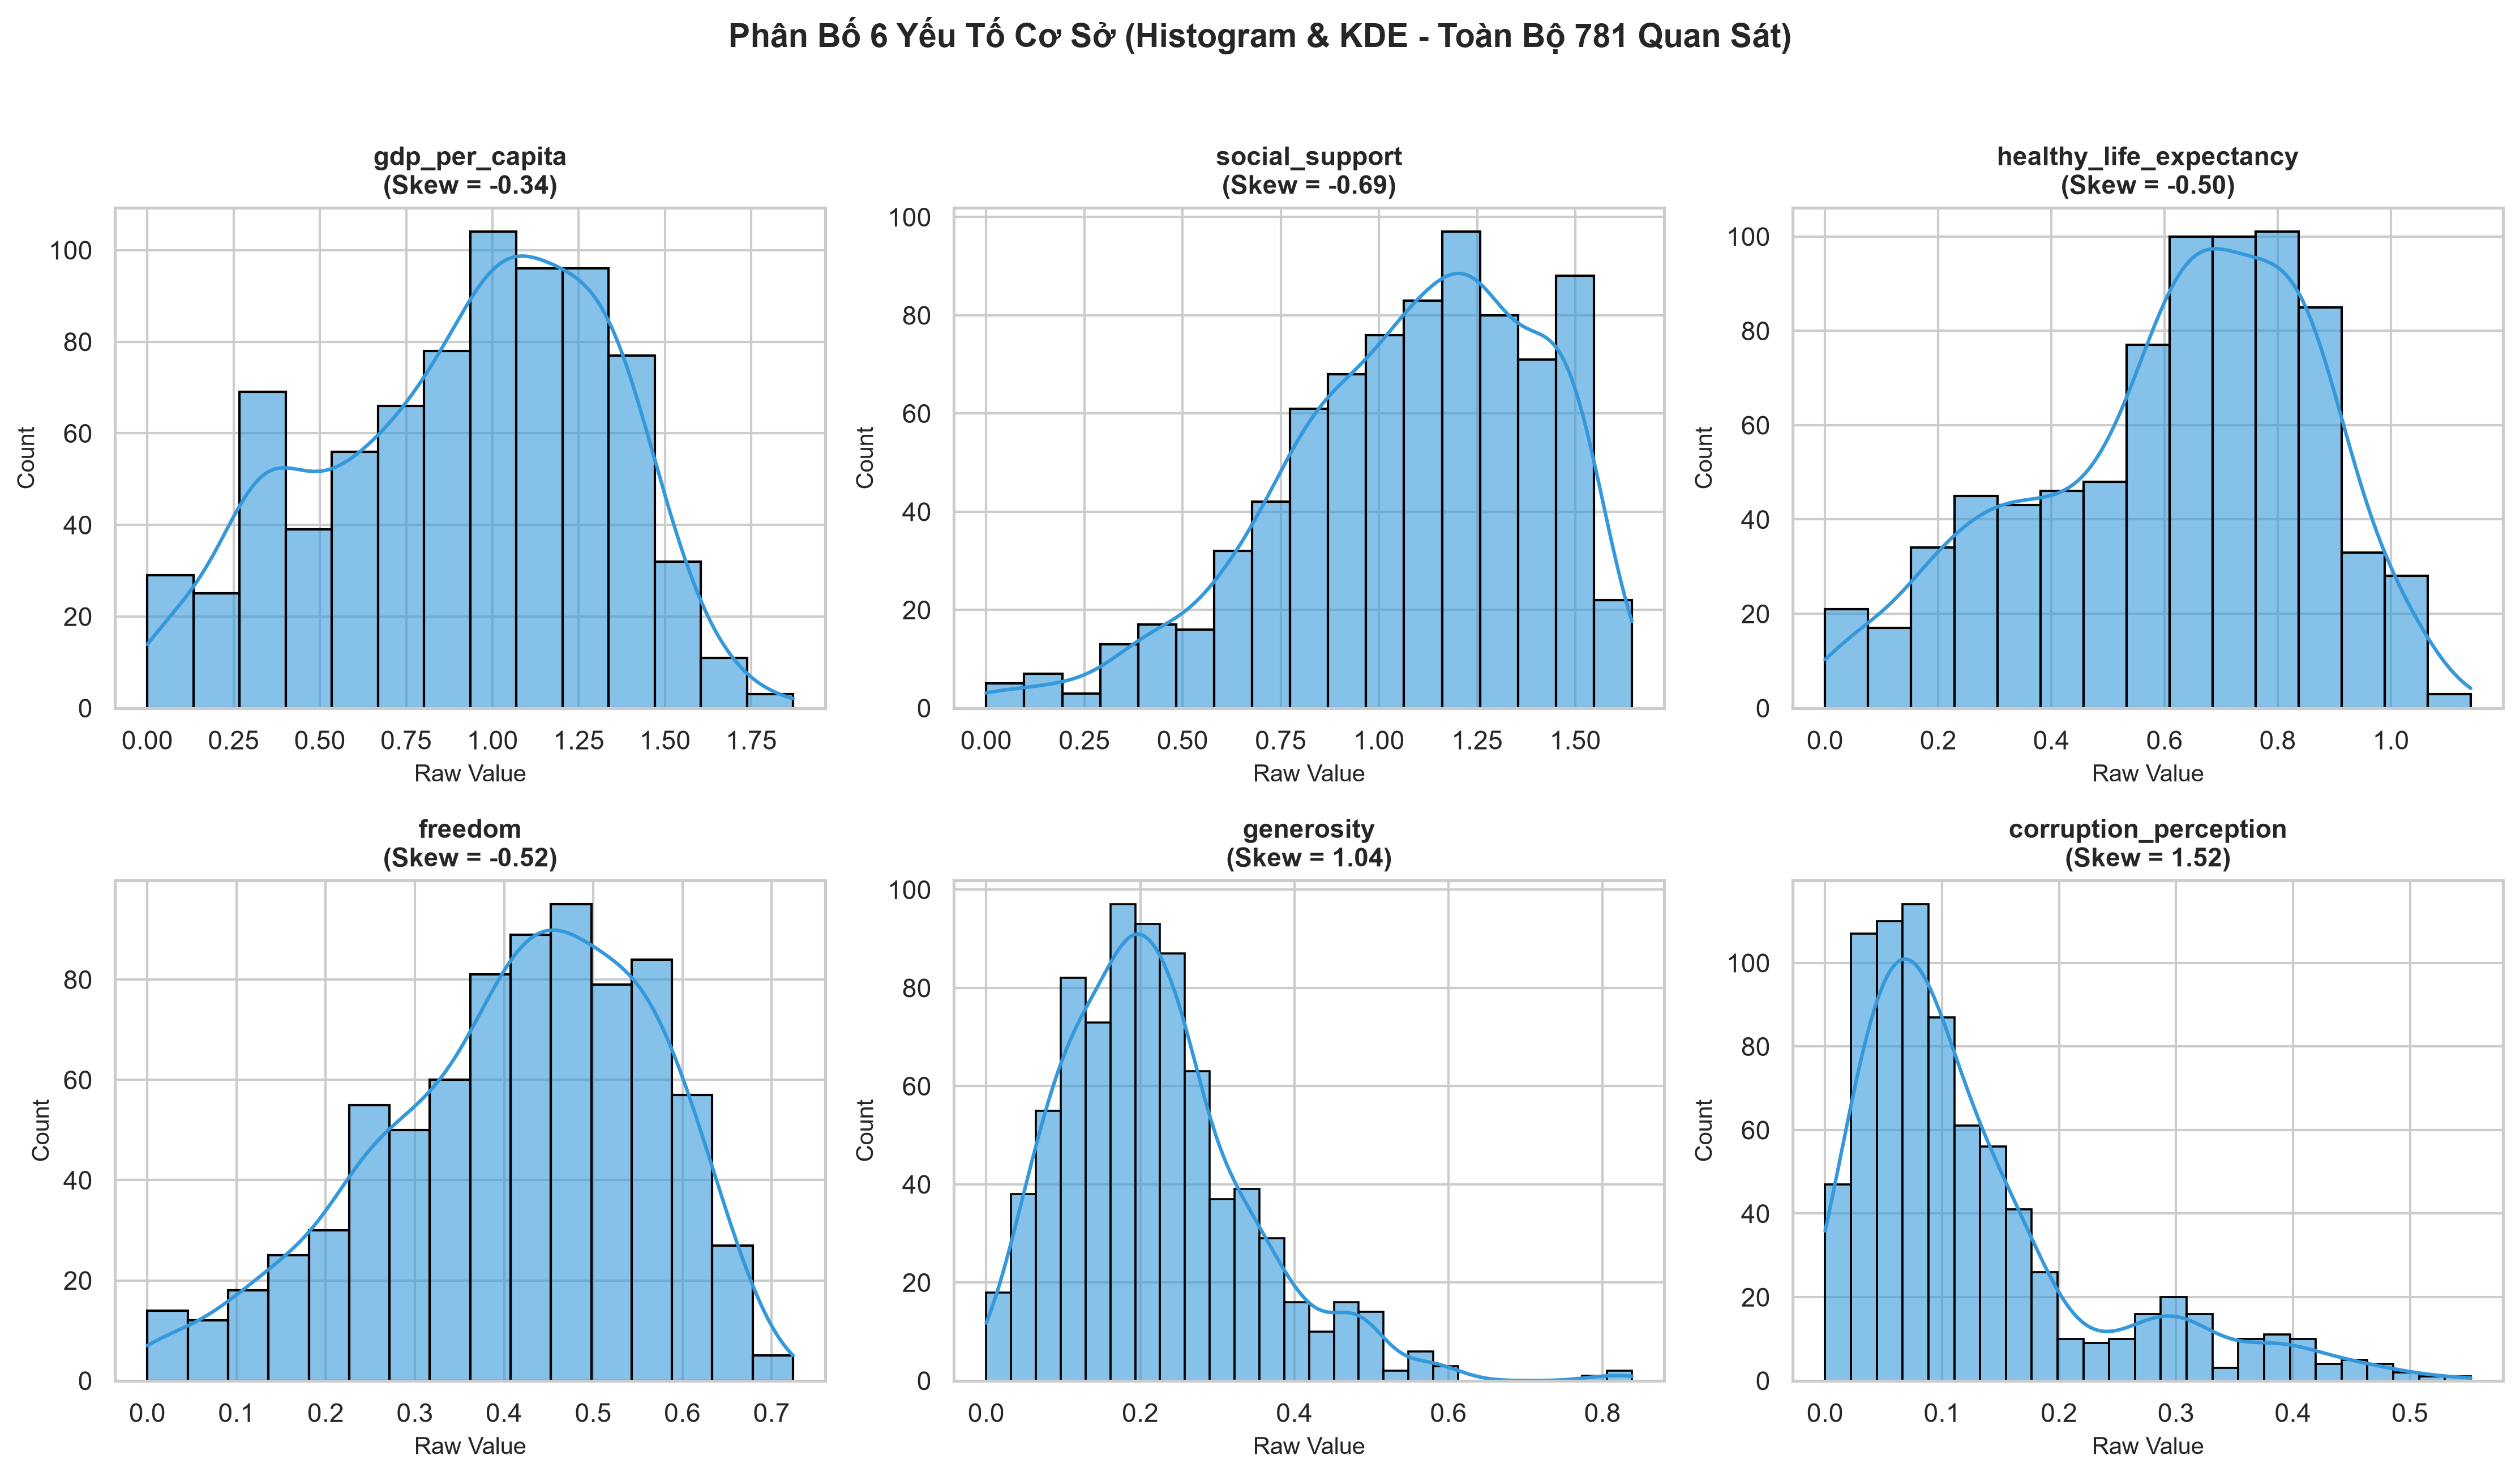

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    skew_val = df[col].skew()
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='#3498db', edgecolor='black', alpha=0.6)
    axes[i].set_title(f'{col}\n(Skew = {skew_val:.2f})', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Raw Value', fontsize=10)
    axes[i].set_ylabel('Count', fontsize=10)

plt.suptitle('Phân Bố 6 Yếu Tố Cơ Sở (Histogram & KDE - Toàn Bộ 781 Quan Sát)', fontsize=14, y=1.02, fontweight='bold')
plt.tight_layout()
plt.savefig(figures_dir / 'feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Phân tích tương quan giữa các đặc trưng và với Happiness Score
Khảo sát ma trận hệ số tương quan Pearson giữa 6 yếu tố cơ sở và `happiness_score` để đánh giá đa cộng tuyến và vai trò của từng yếu tố đối với hạnh phúc.

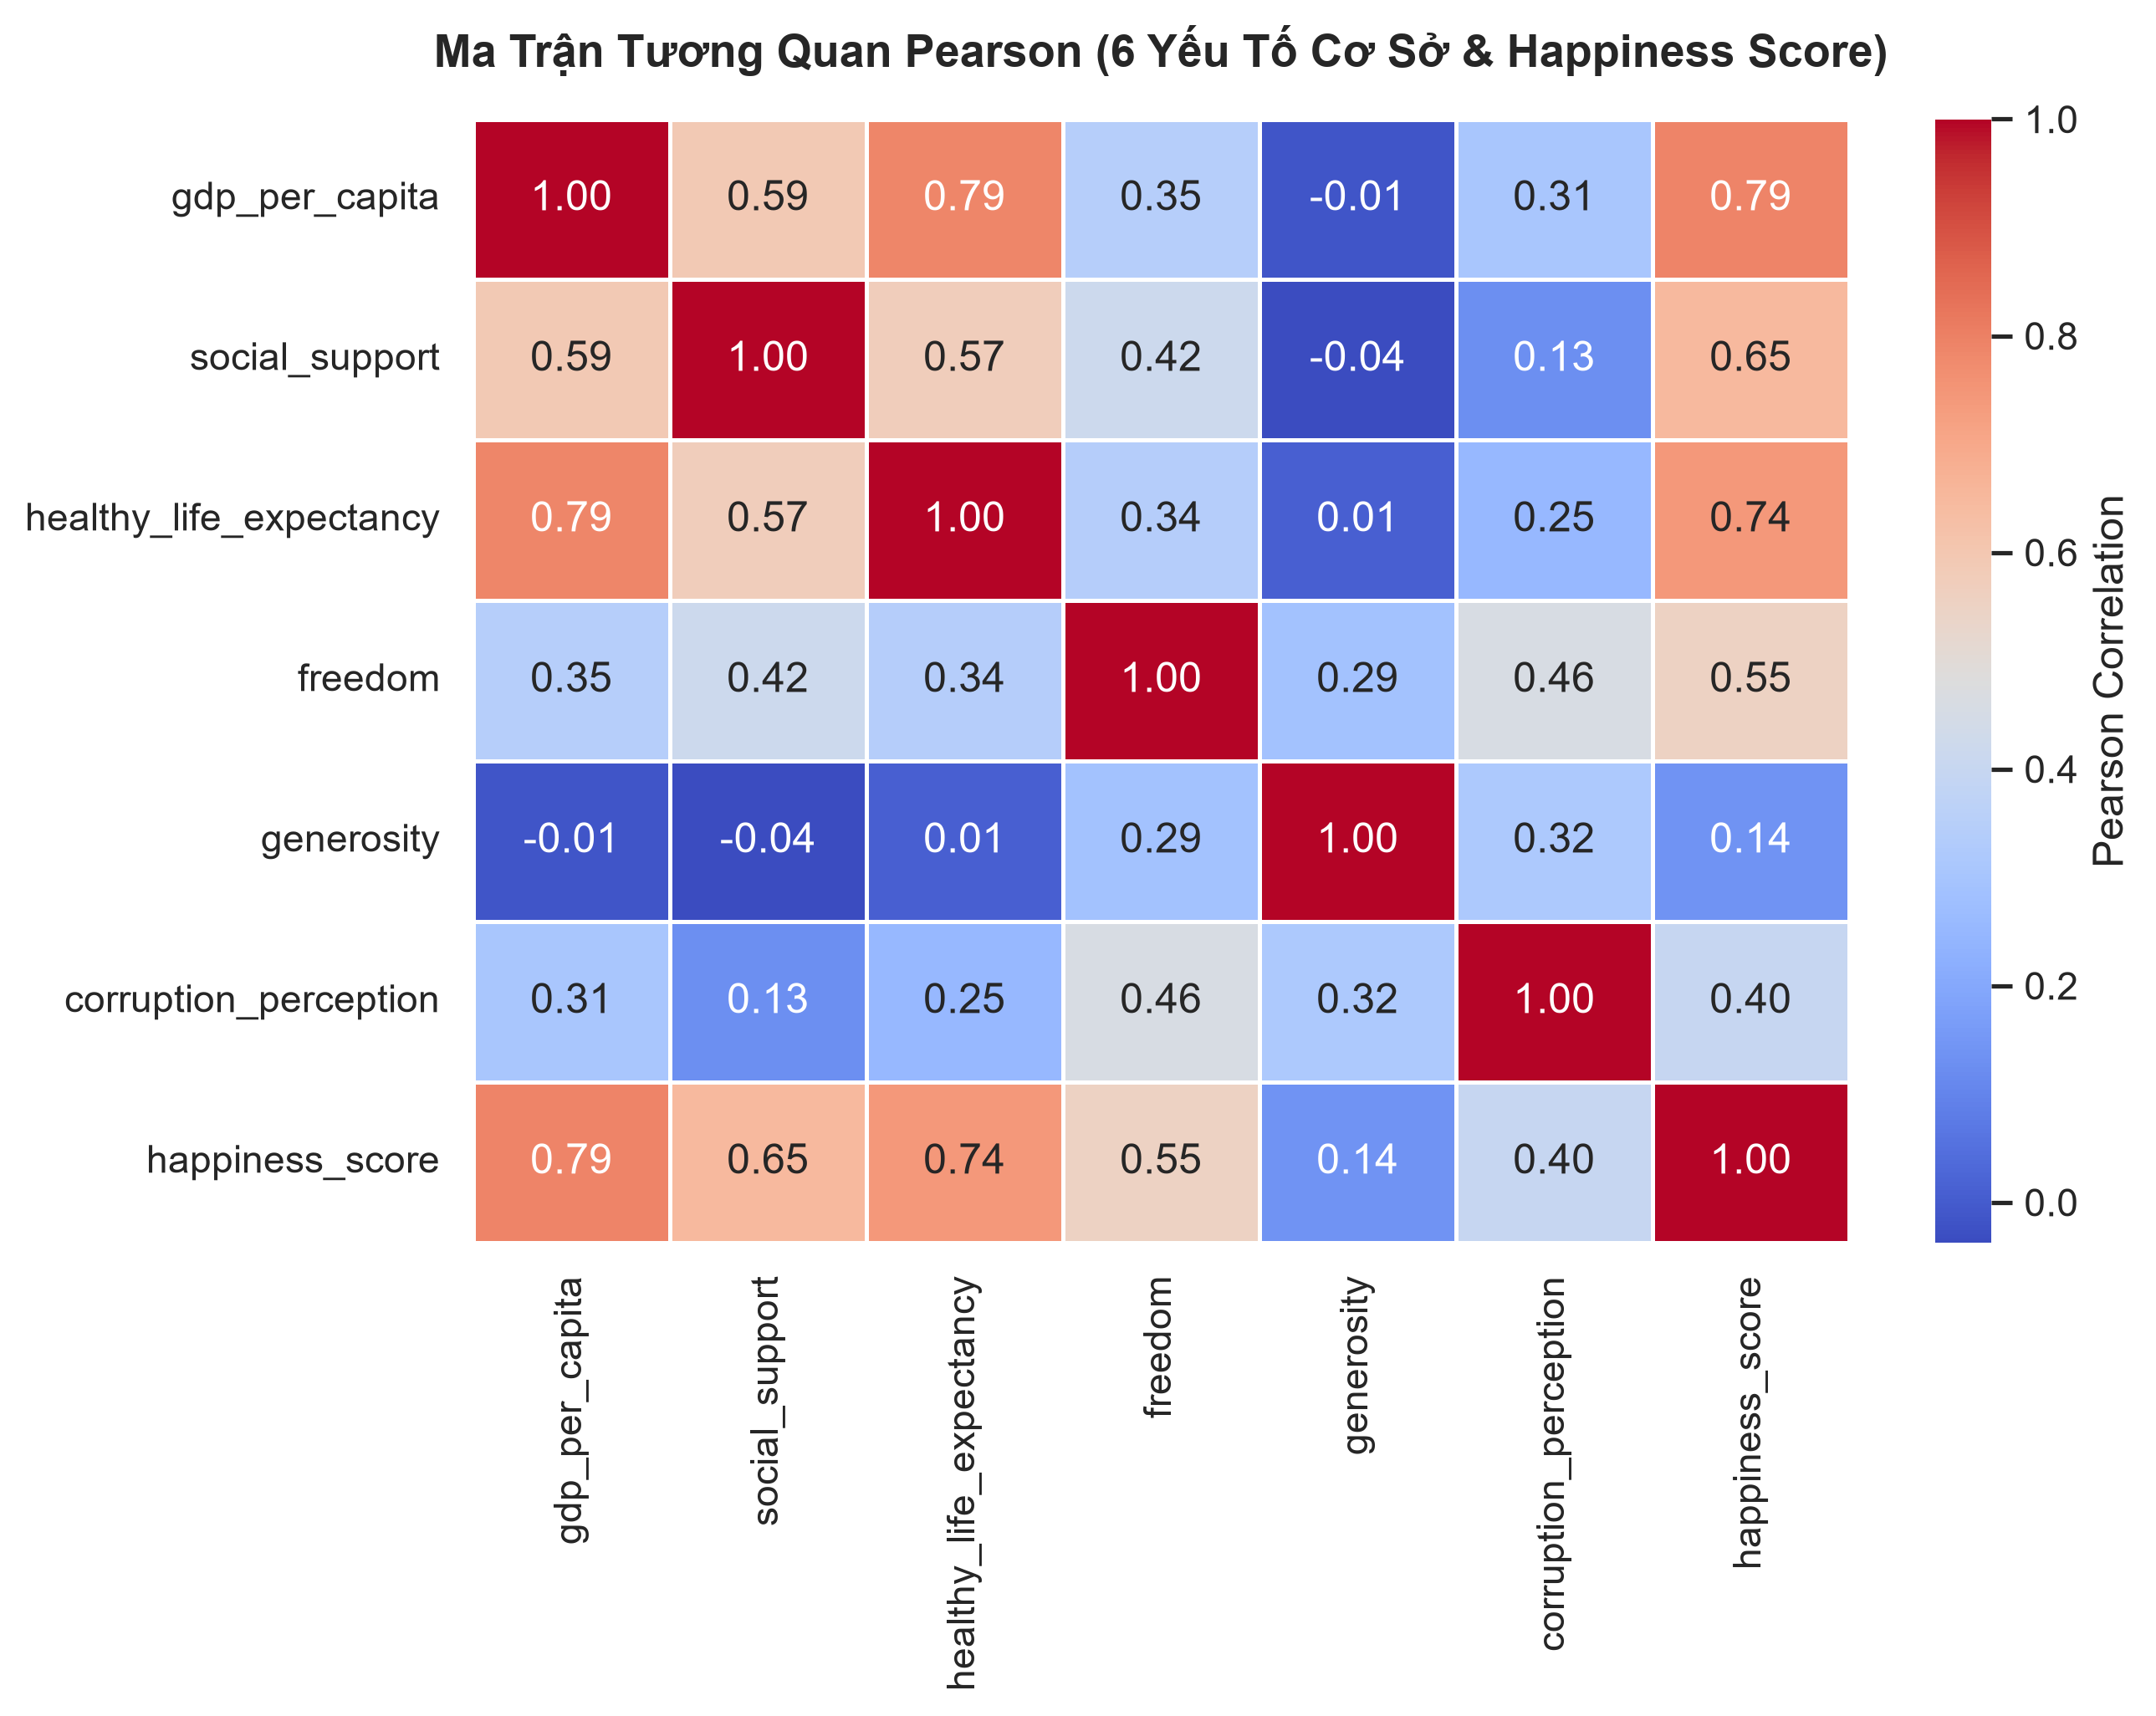

In [4]:
corr_cols = feature_cols + ['happiness_score']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.8, cbar_kws={'label': 'Pearson Correlation'})
plt.title('Ma Trận Tương Quan Pearson (6 Yếu Tố Cơ Sở & Happiness Score)', fontsize=13, pad=15, fontweight='bold')
plt.tight_layout()
plt.savefig(figures_dir / 'correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Phát hiện và đánh giá ngoại lệ (Outlier Detection qua Boxplots)
Đưa 6 đặc trưng về cùng thang đo $[0, 1]$ (Min-Max) để trực quan hóa đồng thời trên biểu đồ hộp (Boxplot), phát hiện các điểm dị biệt (outliers) ở `corruption_perception` và `generosity`.

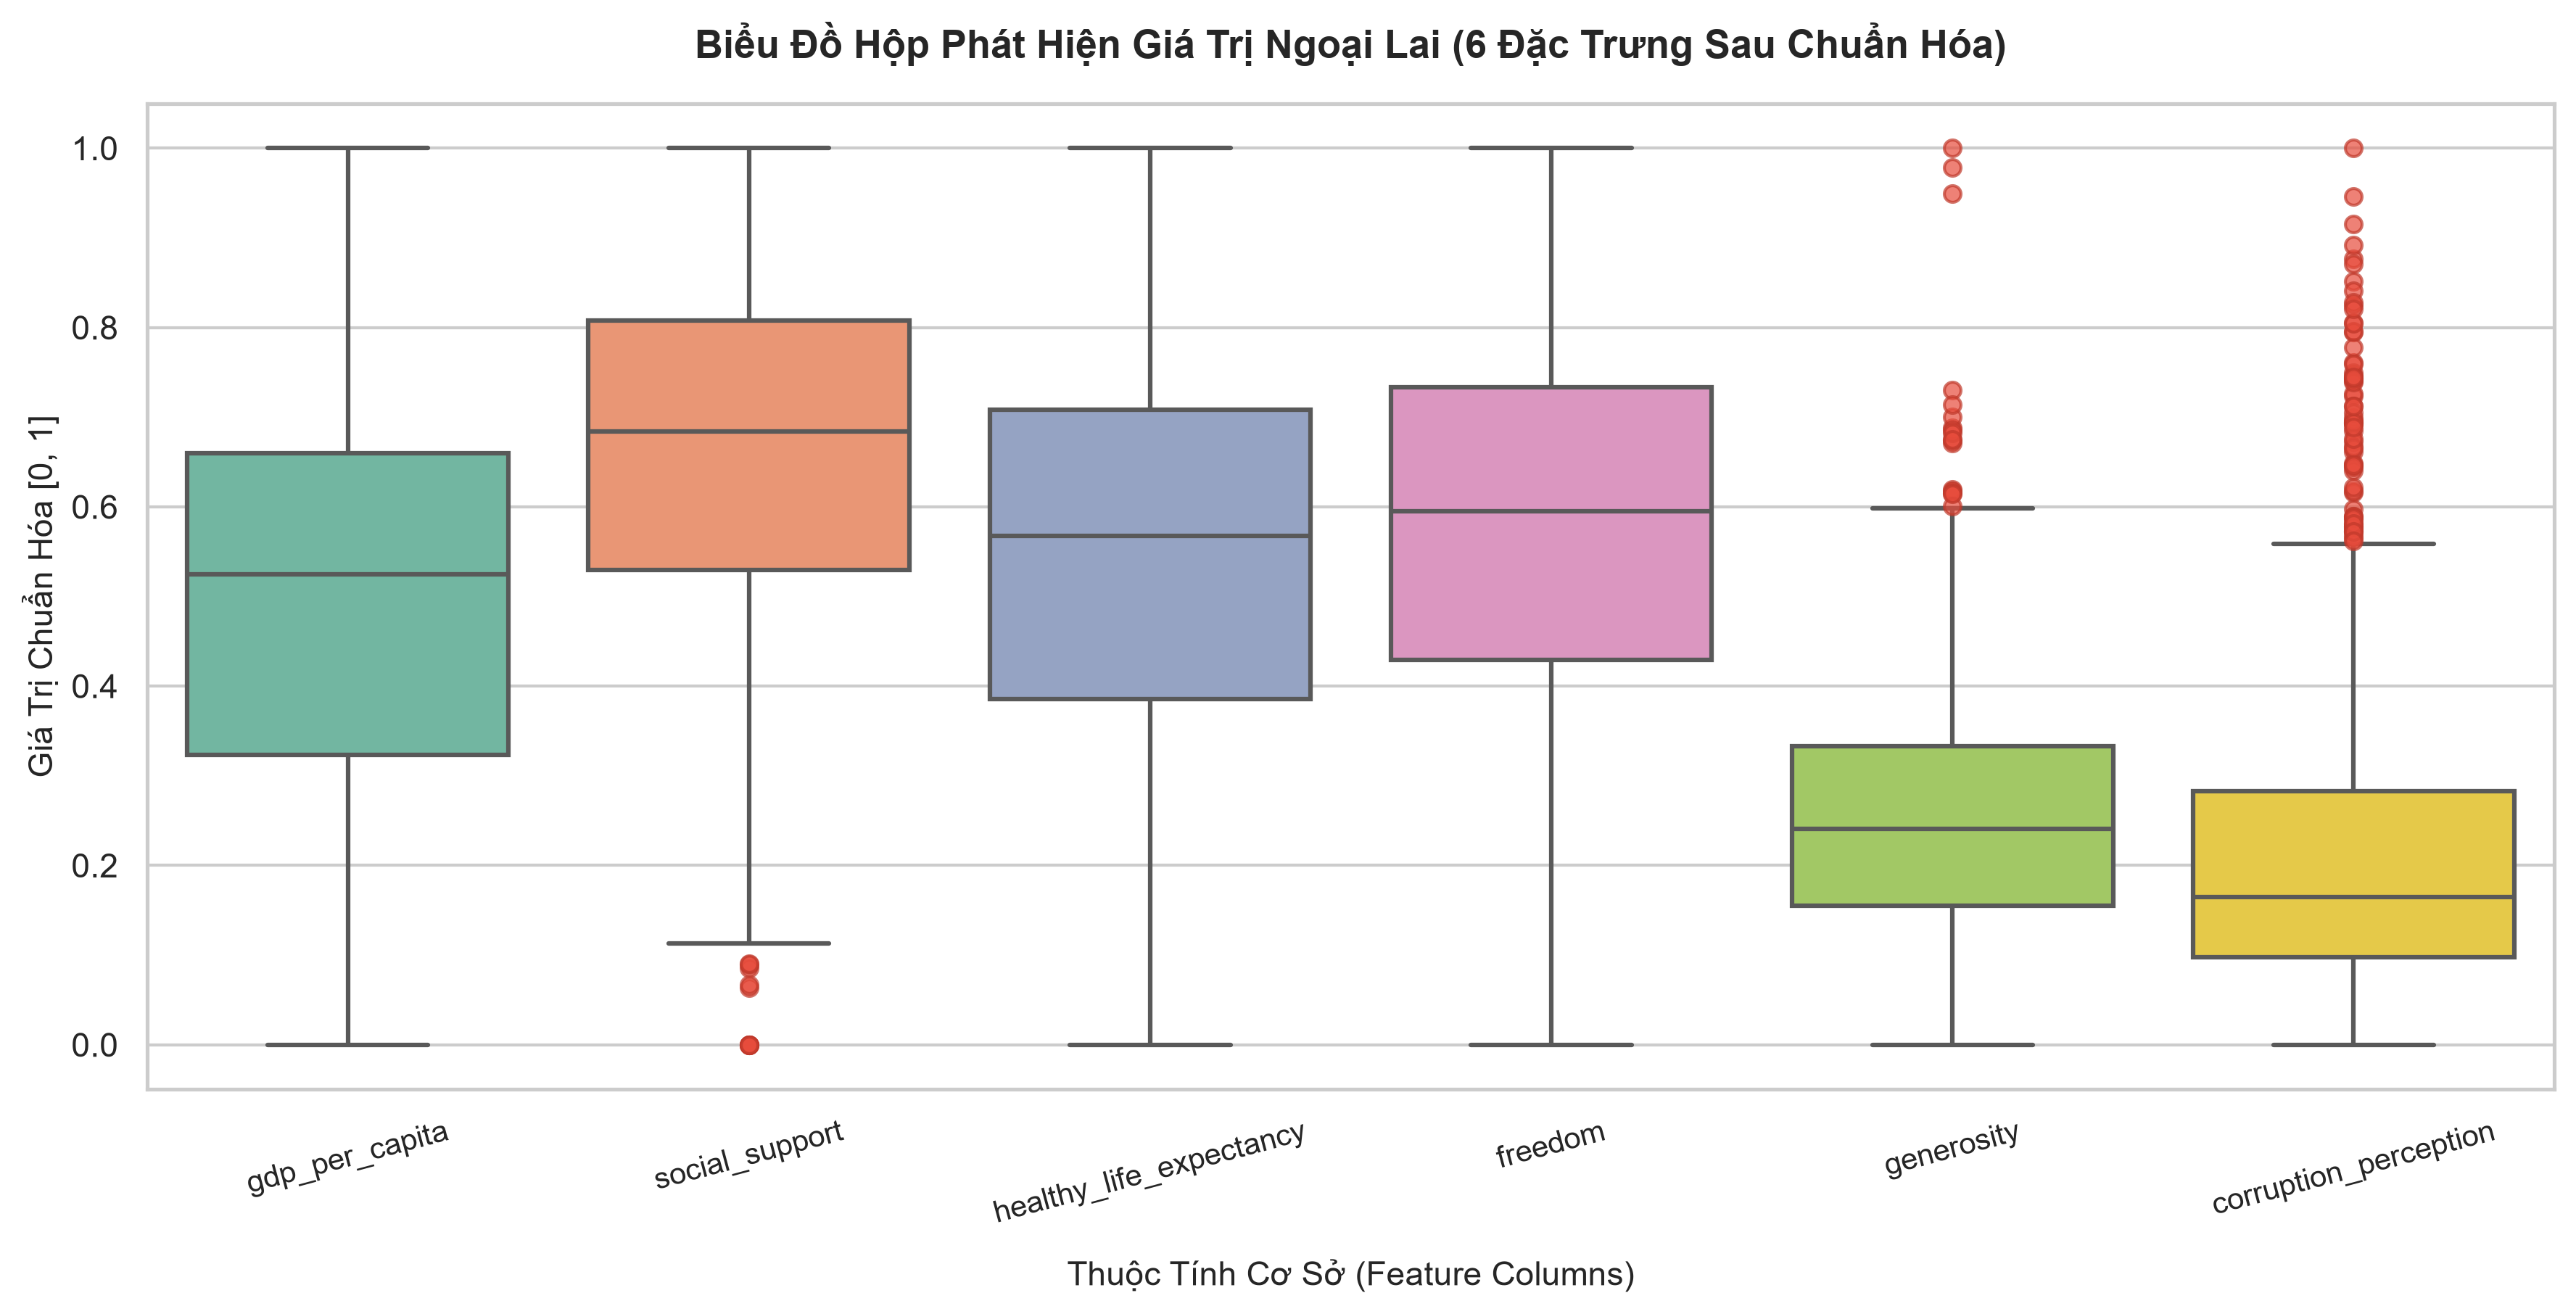

In [5]:
# Chuẩn hóa min-max để hiển thị boxplot đồng nhất trên trục [0, 1]
sub = df[feature_cols]
scaled = (sub - sub.min()) / (sub.max() - sub.min())

plt.figure(figsize=(12, 6.2))
flierprops = dict(marker='o', markersize=5.5, markerfacecolor='#e74c3c', markeredgecolor='#c0392b', alpha=0.7)
sns.boxplot(data=scaled, palette='Set2', flierprops=flierprops, linewidth=1.5)

plt.title('Biểu Đồ Hộp Phát Hiện Giá Trị Ngoại Lai (6 Đặc Trưng Sau Chuẩn Hóa)', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Thuộc Tính Cơ Sở (Feature Columns)', fontsize=11, labelpad=10)
plt.ylabel('Giá Trị Chuẩn Hóa [0, 1]', fontsize=11)
plt.ylim(-0.05, 1.05)
plt.xticks(rotation=15, fontsize=10)
plt.tight_layout()
plt.savefig(figures_dir / 'boxplots_outliers.png', dpi=300, bbox_inches='tight')
plt.show()